In [69]:
# import libraries
import numpy as np
import pandas as pd
from pathlib import Path

In [70]:
# set data directory
DATA_DIR = Path("data/sets")

# combine every saved set
pokemon_all = pd.concat(
    [pd.read_csv(path, dtype={"number": str, "product_id": str, "variant": str}, parse_dates=["date"]) for path in DATA_DIR.glob("*.csv")],
    ignore_index=True
)

# 
sets_df = pd.read_csv("data/sets_info.csv", parse_dates=["release_date"])
pokemon_all = pokemon_all.merge(sets_df, on="set_slug", how="left")


In [71]:
# cleaning
pokemon_all["variant"] = pokemon_all["variant"].fillna("Standard")
pokemon_all["price"] = pokemon_all["price"].replace(0, np.nan)
pokemon_all["date"] = pokemon_all["date"].dt.to_period("M").dt.to_timestamp()
pokemon_all["decade"] = (pokemon_all["release_date"].dt.year // 10) * 10



for col in ["grade", "set_slug", "set_name", "language", "name", "variant"]:
    pokemon_all[col] = pokemon_all[col].astype("category")

In [ ]:
pokemon_all.info()

pokemon_all["variant"].unique()
pokemon_all["grade"].unique()

In [79]:
latest = pokemon_all[
    (pokemon_all["variant"] == "Standard") 
    & (pokemon_all["grade"] == "Ungraded")
    & (pokemon_all["date"] == pokemon_all["date"].max())
    ]

set_prices = (
    latest.groupby("set_name", observed=True)
    .agg(price=("price", "median"), decade=("decade", "first"))
    .dropna(subset=["decade"])
    .reset_index()
)
set_prices["decade"] = set_prices["decade"].astype(int).astype(str) + "s"

set_prices.sort_values('price', ascending=False)

,set_name,price,decade
116,Pokemon Rumble,133.335,2000s
127,Pokemon Southern Islands,48.665,2000s
95,Pokemon POP Series 4,39.990,2000s
16,Pokemon Best of Game,39.760,2000s
96,Pokemon POP Series 5,30.540,2000s
...,...,...,...
91,Pokemon Obsidian Flames,0.280,2020s
120,Pokemon Scarlet & Violet Energy,0.260,2020s
118,Pokemon Scarlet & Violet,0.250,2020s
144,Pokemon Trick or Trade 2023,0.230,2020s


TypeError: unsupported operand type(s) for /: 'str' and 'str'

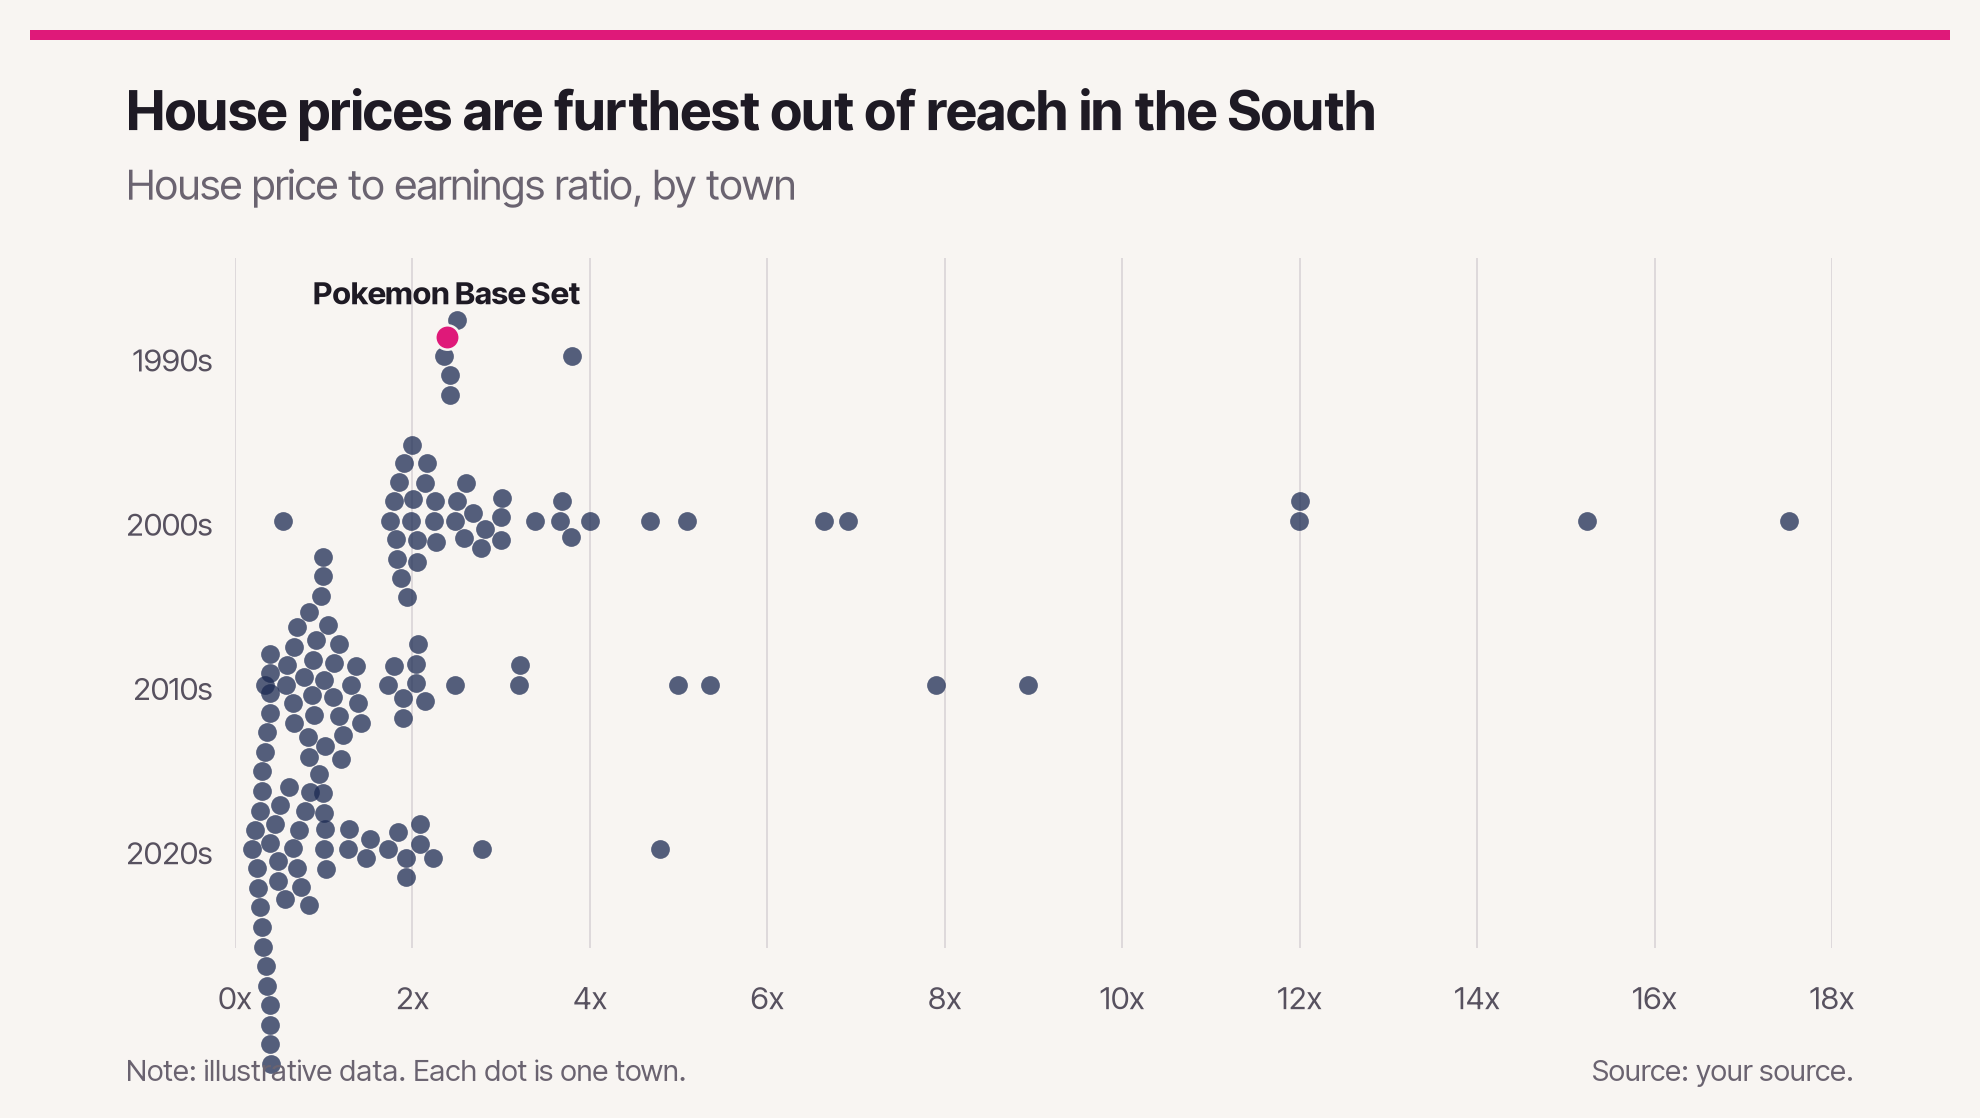

In [ ]:
# ================================
# BEESWARM — every point visible
# ================================
# Works with any data: one row per point with a value and a name (and a group for version 1).
# Set the column names, swap in your data, and list any points to highlight.
# Two versions:
#   1. grouped: one swarm per category, stacked down the page
#   2. single: one big swarm across the page, with chosen points highlighted and labelled

# %%
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chartgazing as cg

# %% ================================
# your data
# ================================
VALUE, GROUP, NAME = "price", "decade", "set_name"

df = set_prices
highlight = ["Pokemon Base Set"]
x_range = (0, 18)
unit_suffix = "x"

title = "House prices are furthest out of reach in the South"
subtitle = "House price to earnings ratio, by town"
note = "Note: illustrative data. Each dot is one town."
source = "Source: your source."

marker_size = 4.5      # dot diameter in points


def swarm(x, diameter):
    """y offsets (same units as x) so dots of the given diameter don't overlap. Greedy, centre-out."""
    order = np.argsort(x)
    ys = np.zeros(len(x))
    placed_x, placed_y = [], []
    for i in order:
        xi = x[i]
        near = [(xj, yj) for xj, yj in zip(placed_x, placed_y) if abs(xj - xi) < diameter]
        candidates = [0.0]
        for xj, yj in near:
            dy = np.sqrt(diameter ** 2 - (xi - xj) ** 2)
            candidates += [yj + dy, yj - dy]
        for c in sorted(candidates, key=abs):
            if all((xi - xj) ** 2 + (c - yj) ** 2 >= diameter ** 2 - 1e-9 for xj, yj in near):
                ys[i] = c
                break
        placed_x.append(xi)
        placed_y.append(ys[i])
    return ys


# %% ================================
# 1. grouped swarms
# ================================
order = sorted(df[GROUP].unique(), reverse=True)   # highest median on top

fig, ax = cg.chart(title, subtitle, note=note, source=source, grid="x")

ax.set_xlim(*x_range)
ax.set_ylim(-0.6, len(order) - 0.4)
ax.set_yticks(range(len(order)), order)
cg.number_axis(ax.xaxis, suffix=unit_suffix)

# the swarm is laid out in points, so fit the layout first to know the final axes size
cg.fit(fig)
bbox = ax.get_window_extent()
pt = 72 / fig.dpi
x_per_pt = np.diff(ax.get_xlim())[0] / (bbox.width * pt)
y_per_pt = np.diff(ax.get_ylim())[0] / (bbox.height * pt)

for yi, group_name in enumerate(order):
    group = df[df[GROUP] == group_name]
    offsets = swarm(group[VALUE].to_numpy() / x_per_pt, marker_size * 1.05) * y_per_pt
    is_hl = group[NAME].isin(highlight).to_numpy()

    ax.scatter(group[VALUE][~is_hl], yi + offsets[~is_hl], s=marker_size ** 2,
               color=cg.SECONDARY, alpha=0.75, linewidth=0, clip_on=False)
    ax.scatter(group[VALUE][is_hl], yi + offsets[is_hl], s=(marker_size * 1.3) ** 2,
               color=cg.PRIMARY, edgecolor=cg.BACKGROUND, linewidth=0.6, zorder=3, clip_on=False)

    for name, xv, yo in zip(group[NAME][is_hl], group[VALUE][is_hl], offsets[is_hl]):
        ax.annotate(name, xy=(xv, yi + yo), xytext=(0, 6), textcoords="offset points",
                    ha="center", va="bottom", fontsize=7.5, fontweight="bold", color=cg.TEXT)

cg.save(fig, cg.EXAMPLES / "09_beeswarm.png")
plt.show()